# Main notebook: Home Credit Default Risk (GCI Global 2026)

This notebook builds the model step by step, following `PLAN.md`. Every change is **measured** with the same cross-validation, so we always know whether it helped or hurt.

- **Phase 2:** preprocessing based on the findings in `eda.ipynb`.
- **Phase 4 (baseline):** LightGBM with 5-fold stratified cross-validation.

> **How to read the scores.** There are two different numbers:
> 1. **Local score (CV AUC):** computed here, on `train.csv`, by hiding part of the data from the model and checking how well it ranks it. Free, instant, unlimited.
> 2. **Public Leaderboard score:** computed by Omnicampus when you upload the CSV, on part of `test.csv`.
>
> The local score is your **practice exam** and the leaderboard is the **mock exam**: if a change raises the CV AUC, it will usually raise the leaderboard score too.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from pathlib import Path

SEED = 42
np.random.seed(SEED)

train = pd.read_csv("input/train.csv")
test = pd.read_csv("input/test.csv")
sample_sub = pd.read_csv("input/sample_submission.csv")
print("train:", train.shape, "| test:", test.shape)

sns.set_theme(style="whitegrid", rc={"axes.titlelocation": "left", "axes.titlesize": 12,
                                     "axes.titleweight": "bold", "grid.color": "#e6e5e0"})

train: (171202, 34) | test: (61500, 33)


## 1. Phase 2: preprocessing

Each step comes from a finding in `eda.ipynb` (section number in brackets).

| Step | Why (EDA) |
|---|---|
| `DAYS_EMPLOYED == 365243` → `NaN` + flag `DAYS_EMPLOYED_ANOM` | It is a code for pensioners, not a real number of days (§7) |
| `OWN_CAR_AGE >= 64` → `NaN` + flag `OWN_CAR_AGE_ANOM` | 64 and 65 are codes, not real car ages (§8) |
| `"XNA"` and `"Unknown"` → `NaN` | Missing values disguised as categories (§9, §10) |
| Drop `FLAG_MOBIL` | Constant: every client but one has 1 (§11) |
| Text columns → `category` type | LightGBM handles categories natively, no one-hot needed |
| **No** mean imputation, **no** scaling | LightGBM uses `NaN` as information (§3) and trees do not need scaling |

> **Golden rule:** train and test go through **exactly the same function**. We process them together so that the categories are identical in both, like translating two documents with the same dictionary.

In [2]:
def preprocess(df, drop_cols=("FLAG_MOBIL",)):
    """Phase 2 cleaning. Applied identically to train and test."""
    df = df.copy()

    # Codes that are not real values -> NaN, keeping the information in a flag
    anom = df["DAYS_EMPLOYED"] == 365243
    df["DAYS_EMPLOYED_ANOM"] = anom.astype(int)
    df.loc[anom, "DAYS_EMPLOYED"] = np.nan

    car_anom = df["OWN_CAR_AGE"] >= 64
    df["OWN_CAR_AGE_ANOM"] = car_anom.astype(int)
    df.loc[car_anom, "OWN_CAR_AGE"] = np.nan

    # Disguised missing values
    df = df.replace({"XNA": np.nan, "Unknown": np.nan})

    # Useless columns
    df = df.drop(columns=[c for c in drop_cols if c in df.columns])
    return df


def build_xy(clean=True, drop_cols=("FLAG_MOBIL",)):
    """Process train and test together and return X, y, X_test."""
    full = pd.concat([train, test], ignore_index=True)
    if clean:
        full = preprocess(full, drop_cols=drop_cols)
    for c in full.select_dtypes(exclude="number").columns:
        full[c] = full[c].astype("category")
    feats = [c for c in full.columns if c not in ("SK_ID_CURR", "TARGET")]
    X = full.loc[: len(train) - 1, feats].reset_index(drop=True)
    X_test = full.loc[len(train):, feats].reset_index(drop=True)
    return X, train["TARGET"], X_test

X, y, X_test = build_xy()
print("Features:", X.shape[1])
X.head(3)

Features: 33


,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,...,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,DAYS_EMPLOYED_ANOM,OWN_CAR_AGE_ANOM
0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,Married,...,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0,0
1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,Married,...,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,1,0
2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,Married,...,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0,0


## 2. Phase 4 (baseline): LightGBM + 5-fold cross-validation

**Why LightGBM:** it is a set of many small decision trees, each one correcting the mistakes of the previous ones. It handles `NaN` and categories by itself and is the usual winner on tabular data.

**Why 5 folds instead of the tutorial's single 70/30 split:** with one split, the score depends on the luck of which clients ended up in validation. With 5 folds, every client is in validation exactly once and we average. It is like taking 5 mock exams instead of 1: the average grade is much more reliable.

**Early stopping:** the model keeps adding trees while the validation AUC improves and stops 100 trees after it stops improving. This prevents memorising the training data (overfitting).

The function returns:
- **OOF AUC** (out-of-fold): the AUC over all clients, each predicted by the model that did *not* see them. **This is our reference score.**
- The **test prediction**: the average of the 5 models.

In [3]:
PARAMS = dict(
    objective="binary", metric="auc",
    learning_rate=0.05, num_leaves=31, min_child_samples=50,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
    n_estimators=5000, random_state=SEED, n_jobs=-1, verbose=-1,
)

def run_cv(X, y, X_test, params=PARAMS, n_splits=5, verbose=True):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    oof = np.zeros(len(X))
    pred_test = np.zeros(len(X_test))
    fold_auc, importances = [], []
    for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y)):
        model = lgb.LGBMClassifier(**params)
        model.fit(X.iloc[tr_idx], y.iloc[tr_idx],
                  eval_set=[(X.iloc[va_idx], y.iloc[va_idx])],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
        oof[va_idx] = model.predict_proba(X.iloc[va_idx])[:, 1]
        pred_test += model.predict_proba(X_test)[:, 1] / n_splits
        fold_auc.append(roc_auc_score(y.iloc[va_idx], oof[va_idx]))
        importances.append(pd.Series(model.booster_.feature_importance("gain"), index=X.columns))
        if verbose:
            print(f"Fold {fold + 1}: AUC {fold_auc[-1]:.4f}  ({model.best_iteration_} trees)")
    auc = roc_auc_score(y, oof)
    if verbose:
        print(f"OOF AUC: {auc:.4f}   (fold std: {np.std(fold_auc):.4f})")
    return dict(auc=auc, fold_std=np.std(fold_auc), oof=oof, pred_test=pred_test,
                importance=pd.concat(importances, axis=1).mean(axis=1).sort_values(ascending=False))

## 3. Experiments: does the preprocessing help?

We compare, always with the same folds and the same model:

| # | Version |
|---|---|
| 0 | Tutorial: Random Forest, 5 features, single 70/30 split (reference value, measured separately: **0.669**) |
| 1 | LightGBM, **all** features, **no** cleaning |
| 2 | LightGBM + Phase 2 cleaning |
| 3 | LightGBM + cleaning + dropping `FLAG_EMP_PHONE` (redundant with the anomaly flag, EDA §7) |

In [4]:
log = [dict(exp=0, version="Tutorial (RF, 5 features, 70/30 split)", cv_auc=0.669, fold_std=np.nan)]

print("=== Exp 1: all features, no cleaning ===")
r1 = run_cv(*build_xy(clean=False))
log.append(dict(exp=1, version="LightGBM, all features, no cleaning", cv_auc=r1["auc"], fold_std=r1["fold_std"]))

print("\n=== Exp 2: + Phase 2 cleaning ===")
r2 = run_cv(*build_xy(clean=True))
log.append(dict(exp=2, version="+ Phase 2 cleaning", cv_auc=r2["auc"], fold_std=r2["fold_std"]))

print("\n=== Exp 3: + drop FLAG_EMP_PHONE ===")
r3 = run_cv(*build_xy(clean=True, drop_cols=("FLAG_MOBIL", "FLAG_EMP_PHONE")))
log.append(dict(exp=3, version="+ drop FLAG_EMP_PHONE", cv_auc=r3["auc"], fold_std=r3["fold_std"]))

log_df = pd.DataFrame(log).set_index("exp")
log_df["vs_previous"] = log_df["cv_auc"].diff()
log_df.round(4)

=== Exp 1: all features, no cleaning ===


Fold 1: AUC 0.7453  (202 trees)


Fold 2: AUC 0.7501  (276 trees)


Fold 3: AUC 0.7542  (345 trees)


Fold 4: AUC 0.7462  (293 trees)


Fold 5: AUC 0.7504  (227 trees)
OOF AUC: 0.7492   (fold std: 0.0032)

=== Exp 2: + Phase 2 cleaning ===


... (7 outputs left out)

Fold 3: AUC 0.7539  (153 trees)


Fold 4: AUC 0.7453  (216 trees)


Fold 5: AUC 0.7524  (221 trees)
OOF AUC: 0.7493   (fold std: 0.0035)


,version,cv_auc,fold_std,vs_previous
exp,,,,
0,"Tutorial (RF, 5 features, 70/30 split)",0.6690,NaN,NaN
1,"LightGBM, all features, no cleaning",0.7492,0.0032,0.0802
2,+ Phase 2 cleaning,0.7499,0.0028,0.0007
3,+ drop FLAG_EMP_PHONE,0.7493,0.0035,-0.0006


**How to read the table:**
- **0.669 → 0.749:** the big jump comes from using **all** the variables and **LightGBM** instead of 5 variables and a Random Forest. This is the step that moves you up the leaderboard.
- **Cleaning (exp 2):** +0.0007. It is a real but small improvement: trees already "isolated" the codes on their own, because a tree can split at `DAYS_EMPLOYED > 300000`. We keep the cleaning anyway, because Phase 3 needs it: a ratio like `DAYS_EMPLOYED / DAYS_BIRTH` would be nonsense with the 365243 code inside.
- **Dropping `FLAG_EMP_PHONE` (exp 3):** -0.0006, so we **keep** the column.

> **Noise vs signal.** The AUC varies about ±0.003 between folds (`fold_std`). Differences of 0.0005 are within that noise, like two students whose grades differ by 0.1 points on one exam: you cannot say who is better. From Phase 3 on we look for changes of **+0.002 or more**.

## 4. Model chosen for this phase: experiment 2

**Which variables does the model use most?** Importance by *gain*: how much each variable improved the trees in total. It confirms the EDA: the `EXT_SOURCE` scores on top, then age and the amounts.

Path in the chart tree: compare many categories → **sorted horizontal bars**.

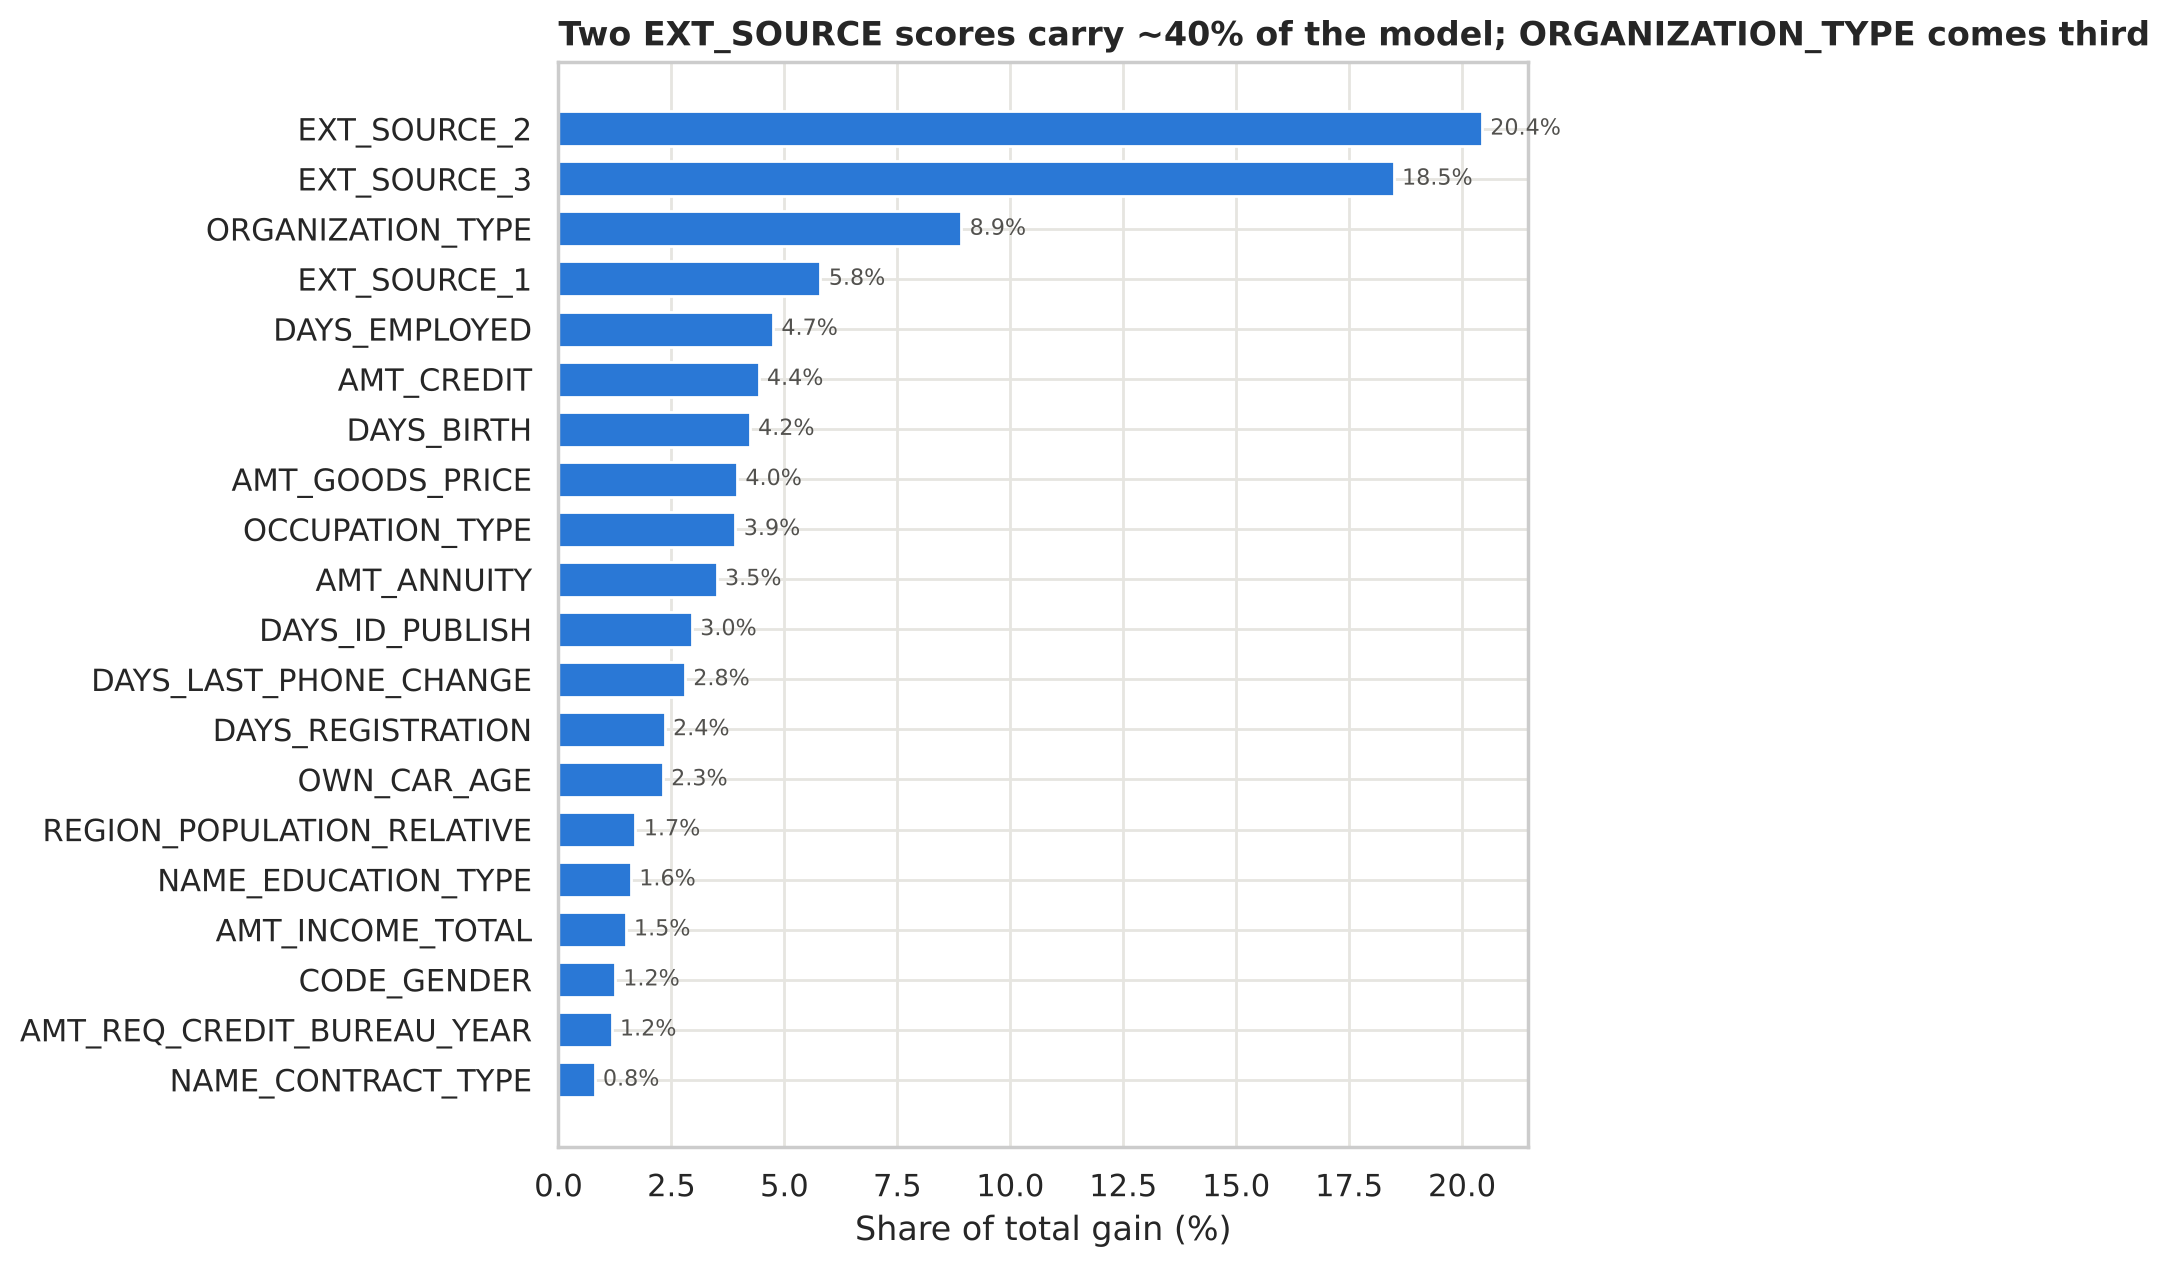

In [5]:
best = r2
imp = (best["importance"] / best["importance"].sum() * 100).head(20).sort_values()

fig, ax = plt.subplots(figsize=(8, 6.5))
bars = ax.barh(imp.index, imp.values, color="#2a78d6", height=0.7)
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8, color="#52514e")
ax.set_xlabel("Share of total gain (%)")
ax.set_title("Two EXT_SOURCE scores carry ~40% of the model; ORGANIZATION_TYPE comes third")
plt.tight_layout(); plt.show()

**What we see:**
- `EXT_SOURCE_2` and `EXT_SOURCE_3` carry almost 40% of the total gain, as the EDA predicted.
- `ORGANIZATION_TYPE` is **third** (8.9%). Careful: with 58 categories, a tree has many ways to split it, and *gain* importance tends to inflate variables like this. It may be useful, or the model may be memorising small sectors. We will compare it against **Count Encoding** in Phase 3.
- `AMT_CREDIT`, `AMT_GOODS_PRICE` and `AMT_ANNUITY` rank in the middle, although on their own they barely separated (EDA §4). The trees are **combining** them, for example "high credit **and** low goods price". That is exactly what we will make explicit in Phase 3 with ratios.

## 5. Submission file

Same format and same row order as `sample_submission.csv`. We save it with a version name so we never overwrite an earlier one.

In [6]:
sub = sample_sub.copy()
assert (sub["SK_ID_CURR"].values == test["SK_ID_CURR"].values).all()   # same order as test
sub["TARGET"] = best["pred_test"]

assert sub["TARGET"].between(0, 1).all() and sub["TARGET"].notna().all()
assert len(sub) == len(sample_sub)

Path("output").mkdir(exist_ok=True)
sub.to_csv("output/submission_v1_lgbm_phase2.csv", index=False)
print(f"Saved output/submission_v1_lgbm_phase2.csv  |  CV AUC {best['auc']:.4f}")
sub.head()

Saved output/submission_v1_lgbm_phase2.csv  |  CV AUC 0.7499


,SK_ID_CURR,TARGET
0,171202,0.026249
1,171203,0.152647
2,171204,0.121009
3,171205,0.105164
4,171206,0.184008


**Next step (Phase 3):** new features (`EXT_SOURCE` combinations, financial ratios, `AGE_YEARS`, `N_MISSING`), added in small groups and kept only if the CV AUC goes up.